# Schritt 4 – Finale Auswertung der Random Graphs

Dieses Notebook liest die auf dem Server erzeugten 1000-Run-CSV-Dateien für `n=25, p=0.15`, `n=50, p=0.15` und `n=100, p=0.02`.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'schritt4_algorithmen_vergleich').exists():
    repo_root = repo_root.parent
step_root = repo_root / 'schritt4_algorithmen_vergleich'
sys.path.insert(0, str(step_root / 'src'))
sys.path.insert(0, str(step_root / 'evaluation'))

import routing_algorithms as routing
from result_analysis import (
    aggregate_results, completeness_table, load_result_directories,
    plot_all_comparisons, validate_summary,
)

EXPECTED_RUNS = 1000
DATASETS = {
    'n25_p015': step_root / 'output' / 'server' / 'synthetic_n25_p015',
    'n50_p015': step_root / 'output' / 'server' / 'synthetic_n50_p015',
    'n100_p002': step_root / 'output' / 'server' / 'synthetic_n100_p002',
}
DISPLAY_NAMES = {
    'n25_p015': 'n=25, p=0.15',
    'n50_p015': 'n=50, p=0.15',
    'n100_p002': 'n=100, p=0.02',
}
OUTPUT_DIR = step_root / 'evaluation' / 'output' / 'synthetic_graphs_runs1000'

## Pilotlauf

Die folgenden Zellen erzeugen bzw. prüfen kleine Pilotdaten und dienen als technische Kontrolle vor der finalen 1000-Run-Auswertung.


In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'schritt4_algorithmen_vergleich').exists():
    repo_root = repo_root.parent

step_root = repo_root / 'schritt4_algorithmen_vergleich'
sys.path.insert(0, str(step_root / 'src'))

import experiment
import routing_algorithms as routing

random_data_dir = step_root / 'output' / 'random_failures_pilot_data'
clustered_data_dir = step_root / 'output' / 'clustered_failures_pilot_data'
plot_dir = step_root / 'evaluation' / 'output' / 'synthetic_graphs_pilot'
for directory in [random_data_dir, clustered_data_dir, plot_dir]:
    directory.mkdir(parents=True, exist_ok=True)

RUNS = 5
FAIL_FACTORS = [0.8, 1.6, 2.4]
FAILURE_STARTS = [0.3, 0.6, 0.9]
FAILURE_DROP = 0.3
SEED = 123

print('Repository:', repo_root)
print('Plots:', plot_dir)

Repository: C:\Users\test\ba-gamous-disjoint
Plots: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\synthetic_graphs_pilot


## Pilotdaten erzeugen oder wiederverwenden

Vollständige vorhandene CSVs werden wiederverwendet. Fehlende oder unvollständige kleine Reihen werden reproduzierbar neu erzeugt.

In [3]:
expected_rows = RUNS * len(routing.ALGORITHMS)

def complete_files(directory, pattern, expected_count):
    files = sorted(directory.glob(pattern))
    complete = (
        len(files) == expected_count
        and all(len(pd.read_csv(path)) == expected_rows for path in files)
    )
    return files if complete else []

random_paths = complete_files(
    random_data_dir, 'algorithms_random_*.csv', 2 * len(FAIL_FACTORS)
)
if not random_paths:
    random_paths = list(map(Path, experiment.run_experiment_series(
        runs=RUNS, failure_types=['link', 'node'], failure_models=['random'],
        algorithms=routing.ALGORITHMS, graph_type='erdos_renyi', nodes=25,
        graph_param=0.15, fail_factors=FAIL_FACTORS,
        output_dir=random_data_dir, seed=SEED,
    )))

clustered_paths = complete_files(
    clustered_data_dir, 'algorithms_clustered_*.csv', 2 * len(FAILURE_STARTS)
)
if not clustered_paths:
    clustered_paths = list(map(Path, experiment.run_experiment_series(
        runs=RUNS, failure_types=['link', 'node'], failure_models=['clustered'],
        algorithms=routing.ALGORITHMS, graph_type='erdos_renyi', nodes=25,
        graph_param=0.15, failure_starts=FAILURE_STARTS,
        failure_drop=FAILURE_DROP, output_dir=clustered_data_dir, seed=SEED,
    )))

csv_paths = random_paths + clustered_paths
print(f'{len(random_paths)} Random-CSV-Dateien')
print(f'{len(clustered_paths)} Clustered-CSV-Dateien')
print(f'Je Datei: {expected_rows} Zeilen')

6 Random-CSV-Dateien
6 Clustered-CSV-Dateien
Je Datei: 30 Zeilen


## Rohdaten aggregieren

Die X-Achse wird in den Plots paper-nah als **Failure Rate** bezeichnet. Technisch entspricht `failureParameter` bei Random Failures dem `failFactor` und bei Clustered Failures dem `failureStart`. Hops und Stretch werden nur über erfolgreiche Routings gemittelt.

In [4]:
raw = pd.concat([pd.read_csv(path) for path in sorted(csv_paths)], ignore_index=True)
for column in ['success', 'hops', 'stretch', 'failFactor', 'failureStart']:
    raw[column] = pd.to_numeric(raw[column], errors='coerce')
raw['hopsSuccessful'] = raw['hops'].where(raw['success'] == 1)
raw['stretchSuccessful'] = raw['stretch'].where(raw['success'] == 1)
raw['failureParameter'] = raw['failFactor'].fillna(raw['failureStart'])

summary = (
    raw.groupby(
        ['failureType', 'failureModel', 'failureParameter', 'algorithm'],
        as_index=False,
    )
    .agg(
        resilience=('success', 'mean'),
        avgHops=('hopsSuccessful', 'mean'),
        avgStretch=('stretchSuccessful', 'mean'),
        samples=('success', 'size'),
        successes=('success', 'sum'),
    )
)
summary_path = plot_dir / 'synthetic_graphs_pilot_summary.csv'
summary.to_csv(summary_path, index=False)

print('Rohdatenzeilen:', len(raw))
print('Aggregierte Zeilen:', len(summary))
summary.groupby(
    ['failureType', 'failureModel', 'failureParameter']
).size().rename('Algorithmen').to_frame()

Rohdatenzeilen: 360
Aggregierte Zeilen: 72


Algorithmen
failureType failureModel failureParameter             
link        clustered    0.3                         6
                         0.6                         6
                         0.9                         6
            random       0.8                         6
                         1.6                         6
                         2.4                         6
node        clustered    0.3                         6
                         0.6                         6
                         0.9                         6
            random       0.8                         6
                         1.6                         6
                         2.4                         6

## Vergleichsplots

Für jede der vier Failure-Kombinationen werden hier Resilience und durchschnittliche Hops ausgegeben. Die X-Achse heißt einheitlich **Failure Rate**; Stretch folgt separat in der nächsten Zelle.

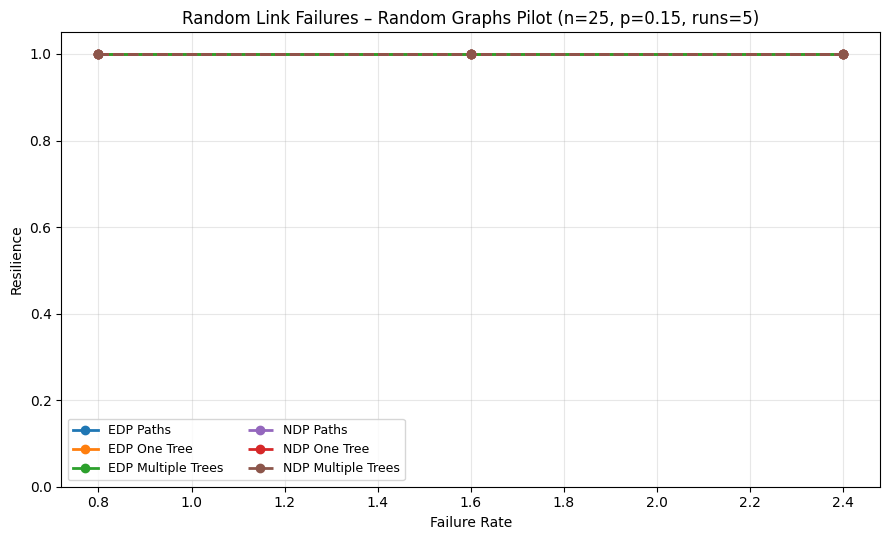

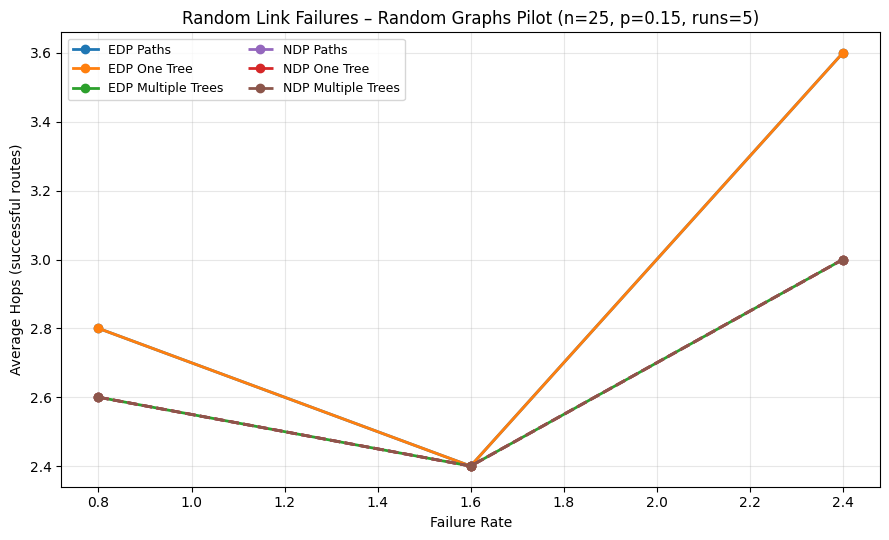

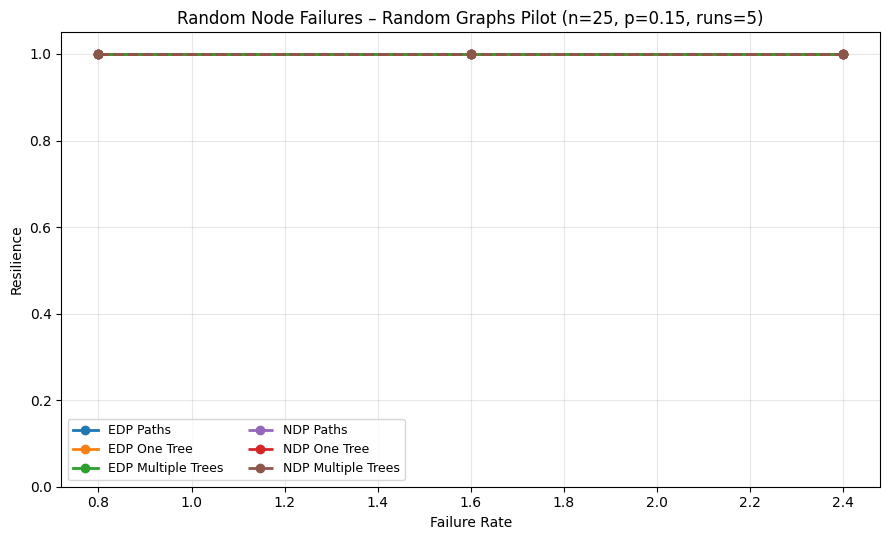

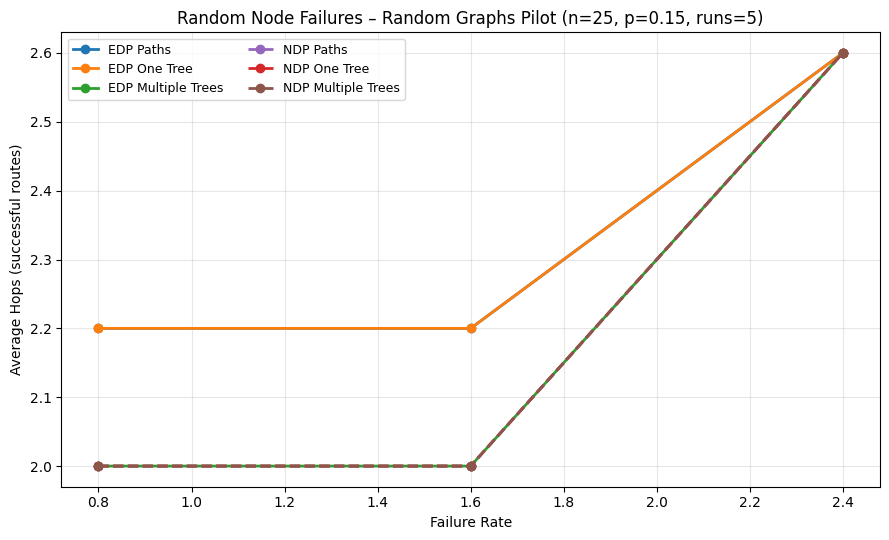

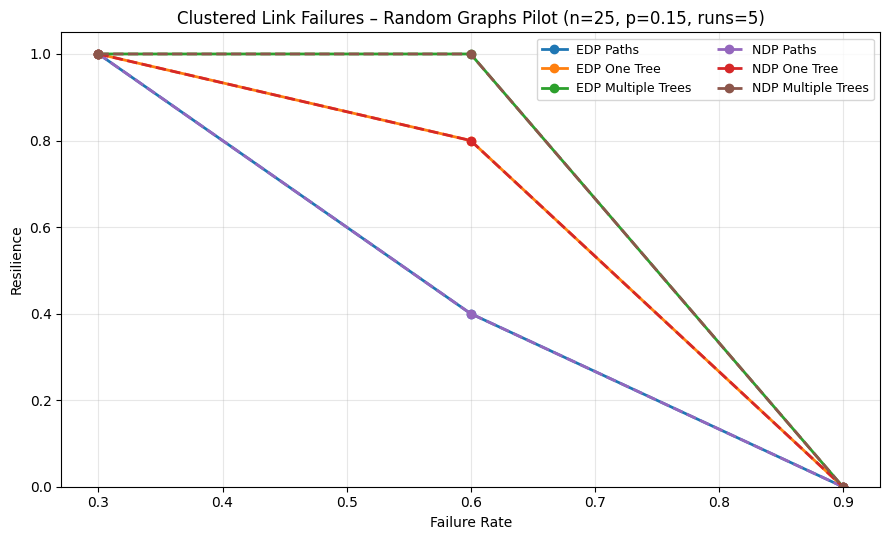

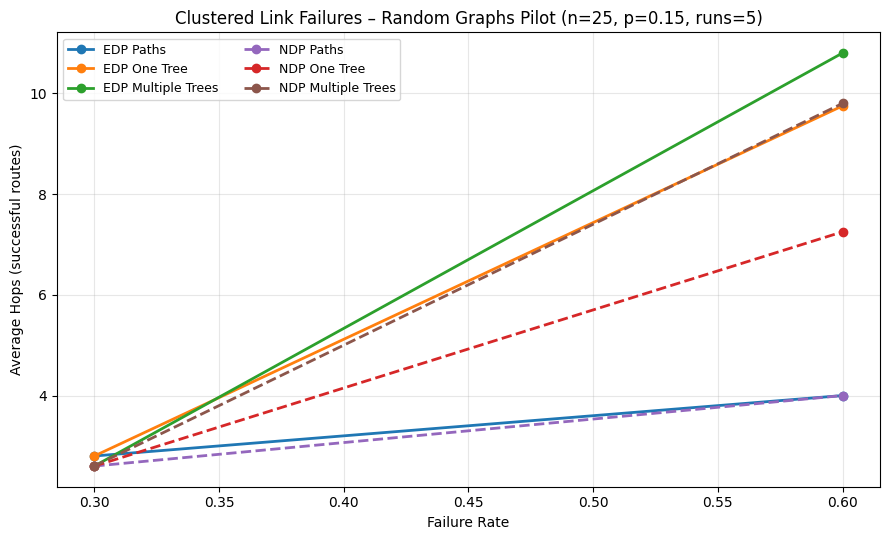

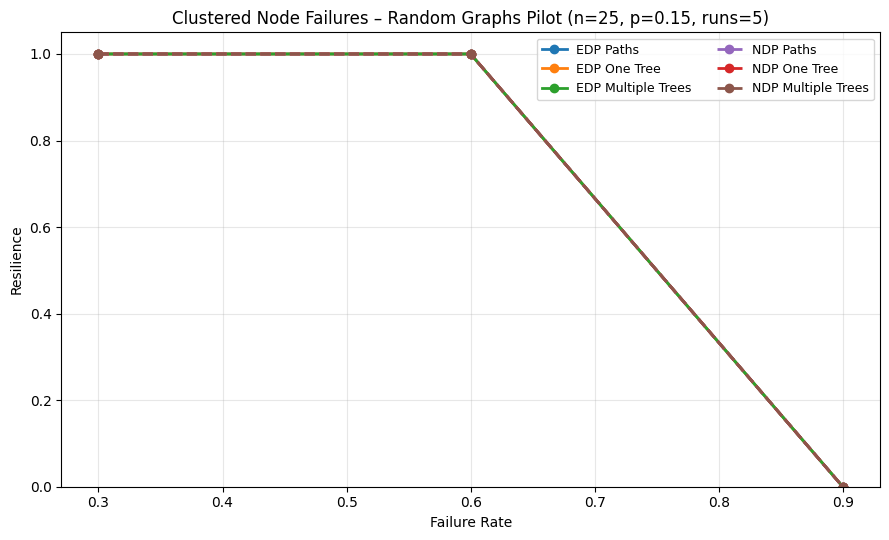

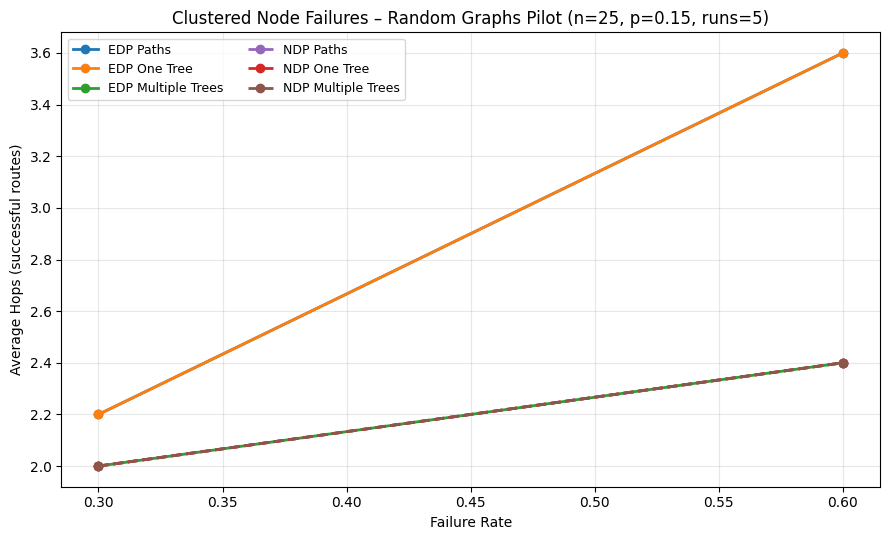

8 Hauptplots erzeugt.


In [5]:
labels = {
    'edp_paths': 'EDP Paths', 'edp_one_tree': 'EDP One Tree',
    'edp_multiple_trees': 'EDP Multiple Trees', 'ndp_paths': 'NDP Paths',
    'ndp_one_tree': 'NDP One Tree', 'ndp_multiple_trees': 'NDP Multiple Trees',
}
colors = {
    'edp_paths': '#1f77b4', 'edp_one_tree': '#ff7f0e',
    'edp_multiple_trees': '#2ca02c', 'ndp_paths': '#9467bd',
    'ndp_one_tree': '#d62728', 'ndp_multiple_trees': '#8c564b',
}

def plot_metric(failure_model, failure_type, metric, ylabel, ylim=None):
    subset = summary[
        (summary['failureModel'] == failure_model)
        & (summary['failureType'] == failure_type)
    ]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for algorithm in routing.ALGORITHMS:
        values = subset[subset['algorithm'] == algorithm].sort_values('failureParameter')
        ax.plot(
            values['failureParameter'], values[metric], marker='o', linewidth=2,
            label=labels[algorithm], color=colors[algorithm],
            linestyle='--' if algorithm.startswith('ndp_') else '-',
        )
    ax.set_xlabel('Failure Rate')
    ax.set_ylabel(ylabel)
    ax.set_title(
        f'{failure_model.title()} {failure_type.title()} Failures – '
        f'Random Graphs Pilot (n=25, p=0.15, runs={RUNS})'
    )
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, fontsize=9)
    fig.tight_layout()
    output = plot_dir / f'{failure_model}_{failure_type}_{metric}.png'
    fig.savefig(output, dpi=180, bbox_inches='tight')
    plt.show()
    return output

plot_paths = []
for failure_model in ['random', 'clustered']:
    for failure_type in ['link', 'node']:
        plot_paths.append(plot_metric(failure_model, failure_type, 'resilience', 'Resilience', (0, 1.05)))
        plot_paths.append(plot_metric(failure_model, failure_type, 'avgHops', 'Average Hops (successful routes)'))

print(f'{len(plot_paths)} Hauptplots erzeugt.')

## Stretch-Plots

Diese Zelle erzeugt den durchschnittlichen Stretch separat, damit die Hauptauswertung übersichtlicher bleibt.


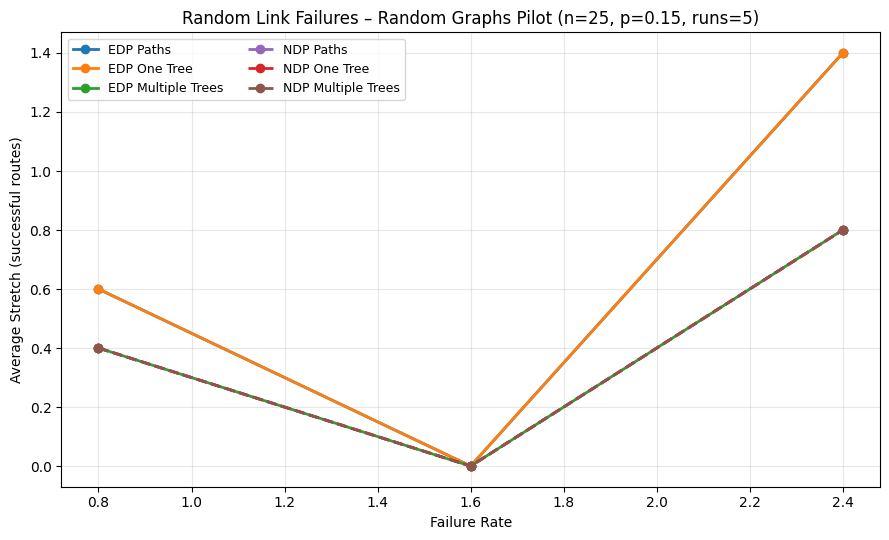

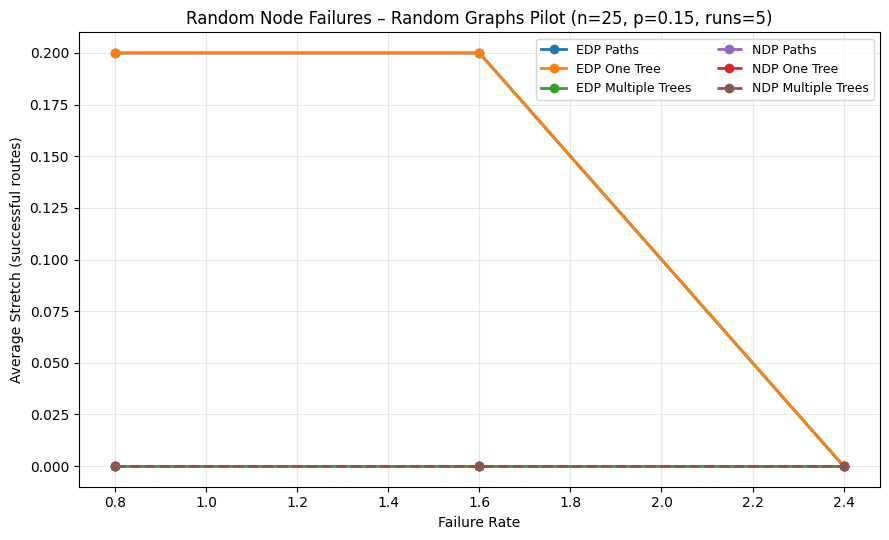

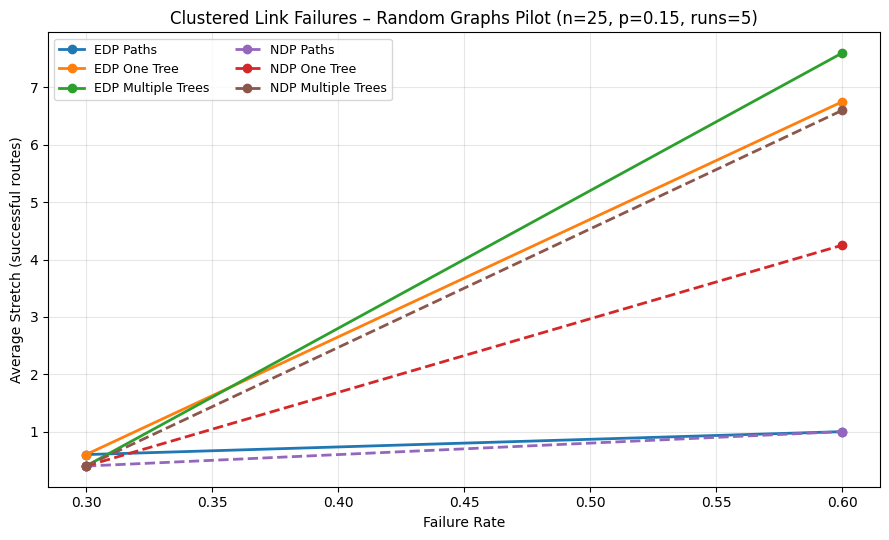

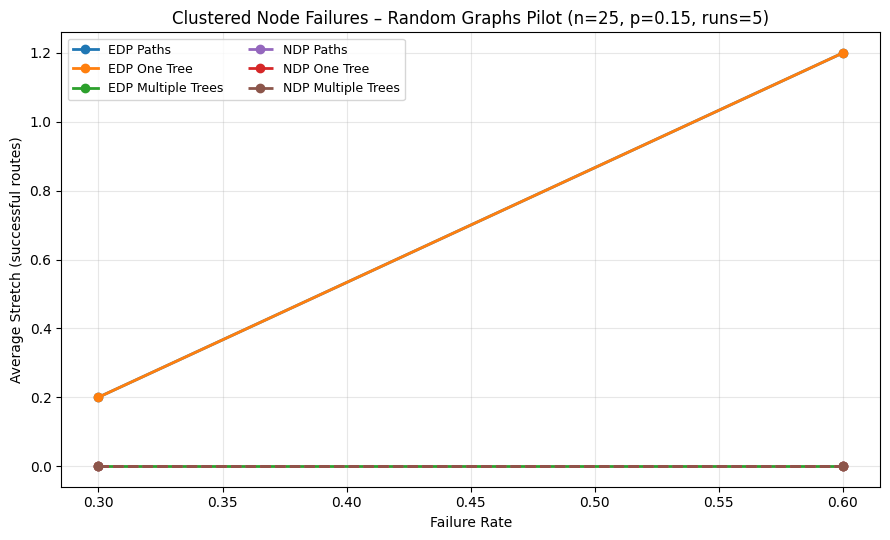

4 Stretch-Plots erzeugt.


In [6]:
stretch_plot_paths = []
for failure_model in ['random', 'clustered']:
    for failure_type in ['link', 'node']:
        stretch_plot_paths.append(plot_metric(failure_model, failure_type, 'avgStretch', 'Average Stretch (successful routes)'))

print(f'{len(stretch_plot_paths)} Stretch-Plots erzeugt.')

## Technische Plausibilitätsprüfung

In [7]:
expected_total = (
    2 * len(FAIL_FACTORS) * expected_rows
    + 2 * len(FAILURE_STARTS) * expected_rows
)
assert len(raw) == expected_total
assert set(raw['algorithm']) == set(routing.ALGORITHMS)
assert set(raw['failureType']) == {'link', 'node'}
assert set(raw['failureModel']) == {'random', 'clustered'}
assert raw.groupby(
    ['failureType', 'failureModel', 'failureParameter', 'algorithm']
).size().eq(RUNS).all()
assert summary['resilience'].between(0, 1).all()
assert len(plot_paths) == 8
assert len(stretch_plot_paths) == 4
assert all(path.exists() and path.stat().st_size > 0 for path in plot_paths + stretch_plot_paths)
assert summary_path.exists() and summary_path.stat().st_size > 0
print('Random-Graph-Pilot vollständig und technisch plausibel.')

Random-Graph-Pilot vollständig und technisch plausibel.


<!-- END_INTEGRIERTER_PILOT -->

## Finale 1000-Run-Auswertung

Ab hier werden die vollstaendigen Serverdaten geladen, geprueft und zu den finalen Abbildungen aggregiert.


## Serverdaten laden und vollständig prüfen

In [8]:
raw_input, files_by_dataset = load_result_directories(DATASETS)
raw, summary = aggregate_results(raw_input)
validate_summary(summary, EXPECTED_RUNS, routing.ALGORITHMS)

print('CSV-Dateien:', sum(len(files) for files in files_by_dataset.values()))
print('Rohdatenzeilen:', len(raw))
print('Aggregierte Zeilen:', len(summary))
completeness_table(summary)

CSV-Dateien: 230
Rohdatenzeilen: 1380000
Aggregierte Zeilen: 1380


algorithms  \
dataset   failureType failureModel failureParameter               
n100_p002 link        clustered    0.3                        6   
                                   0.4                        6   
                                   0.5                        6   
                                   0.6                        6   
                                   0.7                        6   
...                                                         ...   
n50_p015  node        random       13.6                       6   
                                   14.4                       6   
                                   15.2                       6   
                                   16.0                       6   
                                   16.8                       6   

                                                     samplesPerAlgorithm  
dataset   failureType failureModel failureParameter                       
n100_p002 link        clustered    0.3                              1000  
                                   0.4                              1000  
                                   0.5                              1000  
                                   0.6                              1000  
                                   0.7                              1000  
...                                                                  ...  
n50_p015  node        random       13.6                             1000  
                                   14.4                             1000  
                                   15.2                             1000  
                                   16.0                             1000  
                                   16.8                             1000  

[230 rows x 2 columns]

## Finale PNG- und SVG-Plots erzeugen

Die X-Achse wird paper-nah einheitlich als **Failure Rate** beschriftet. Technisch entspricht sie bei Random Failures dem `failFactor` und bei Clustered Failures dem `failureStart`.

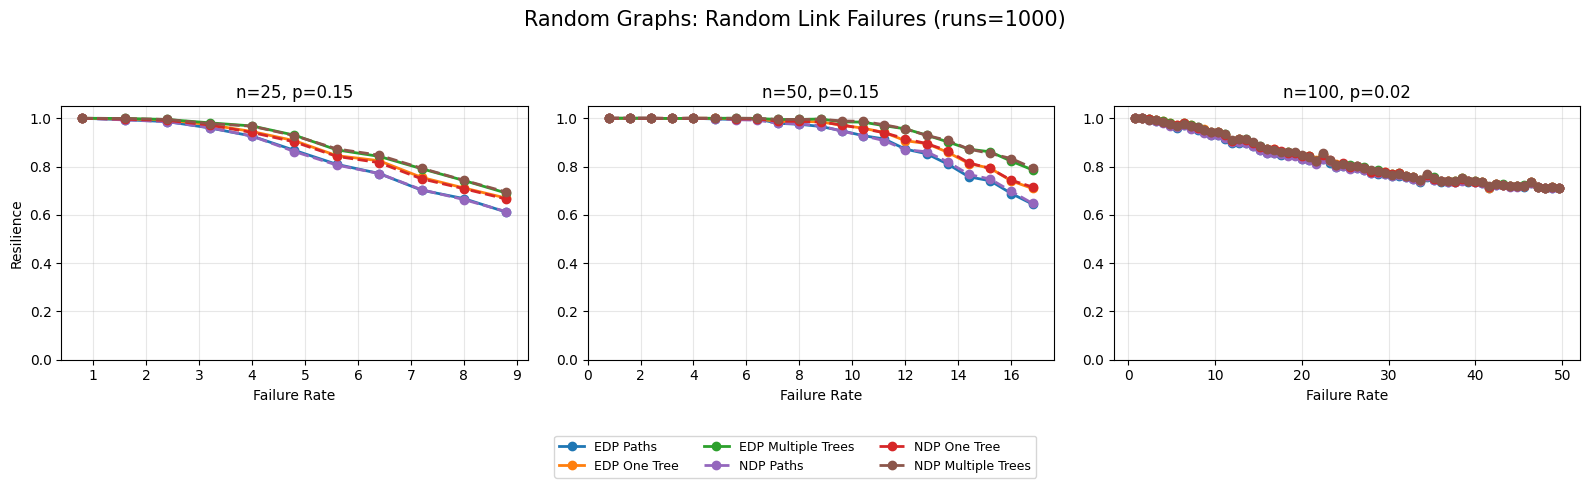

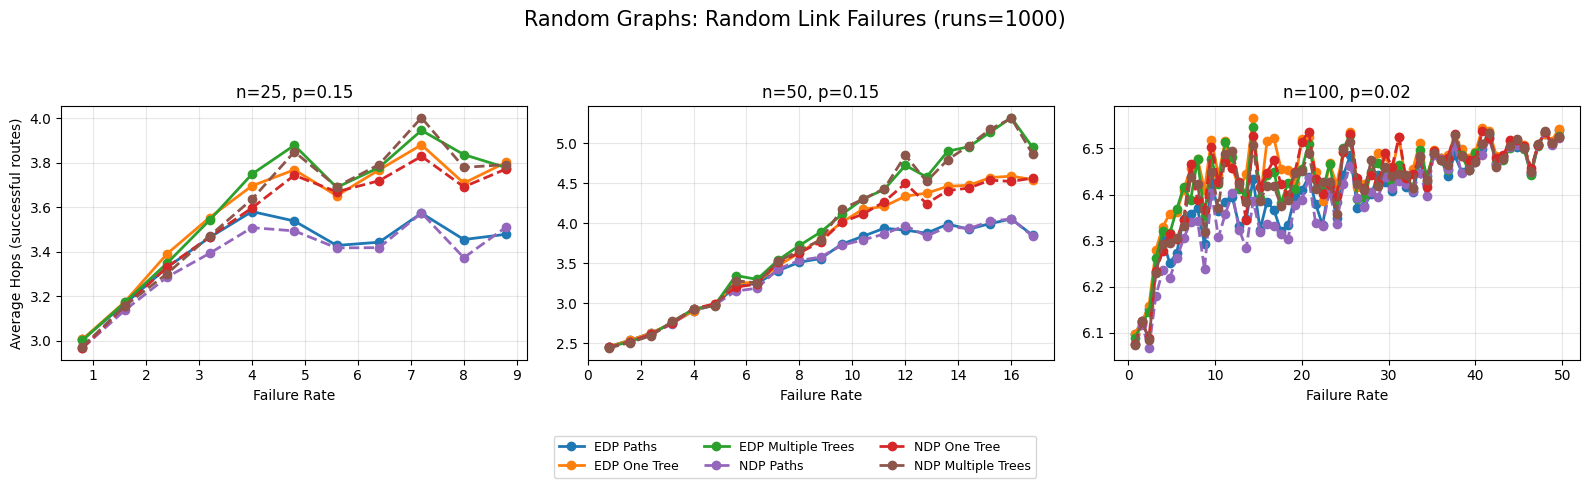

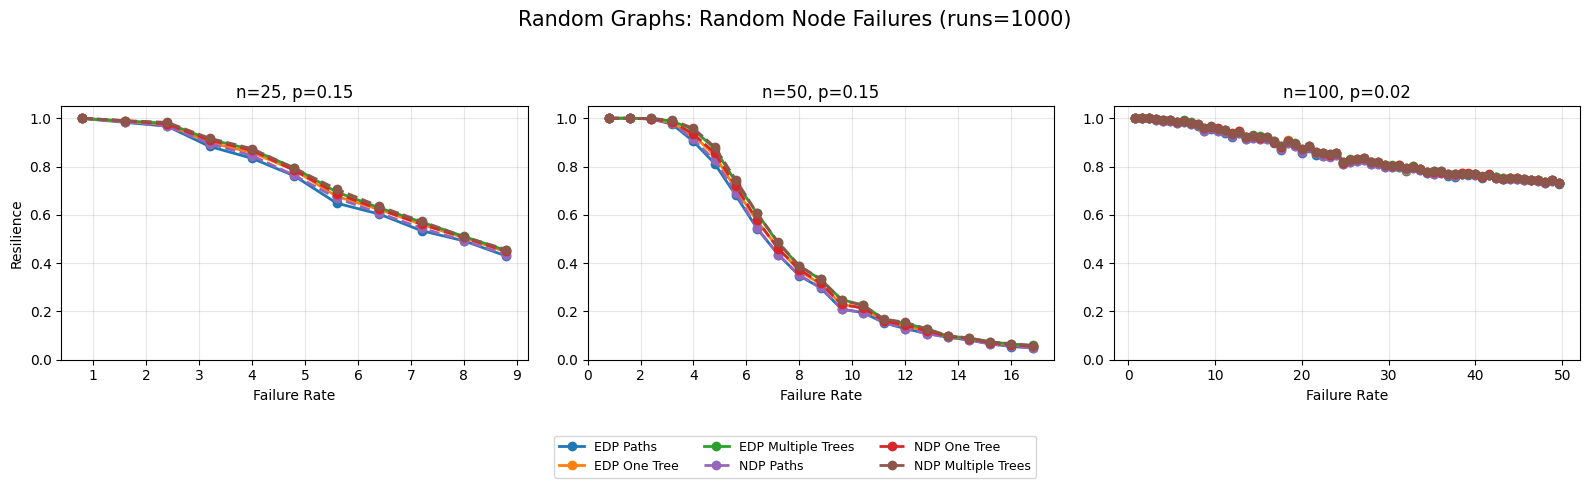

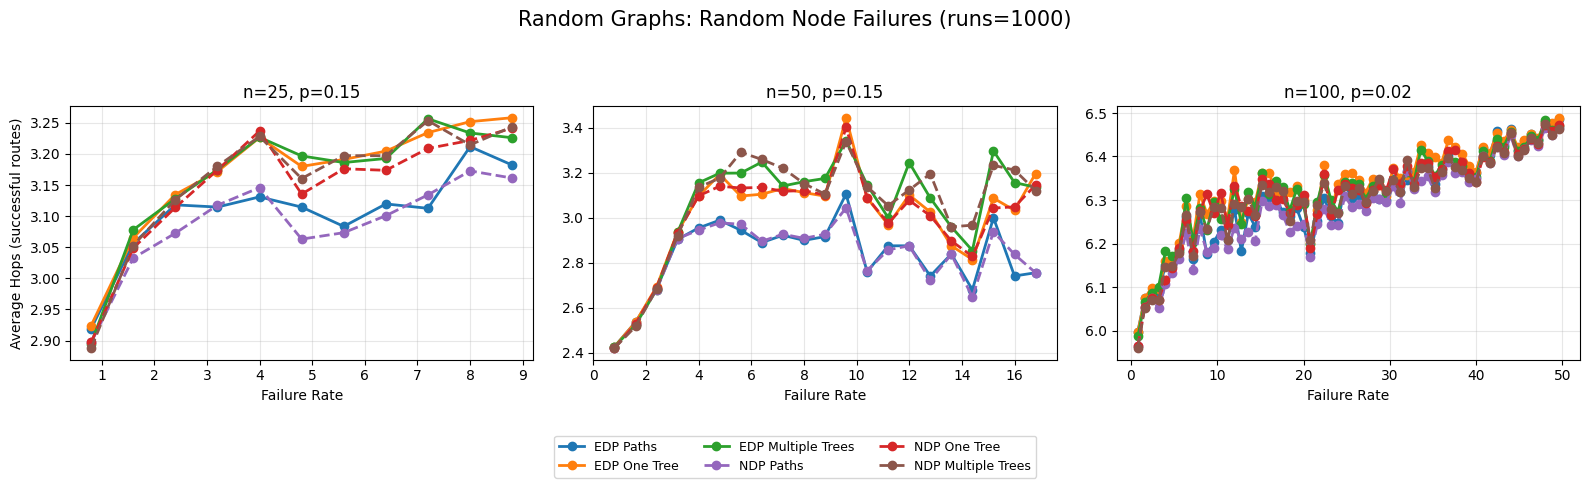

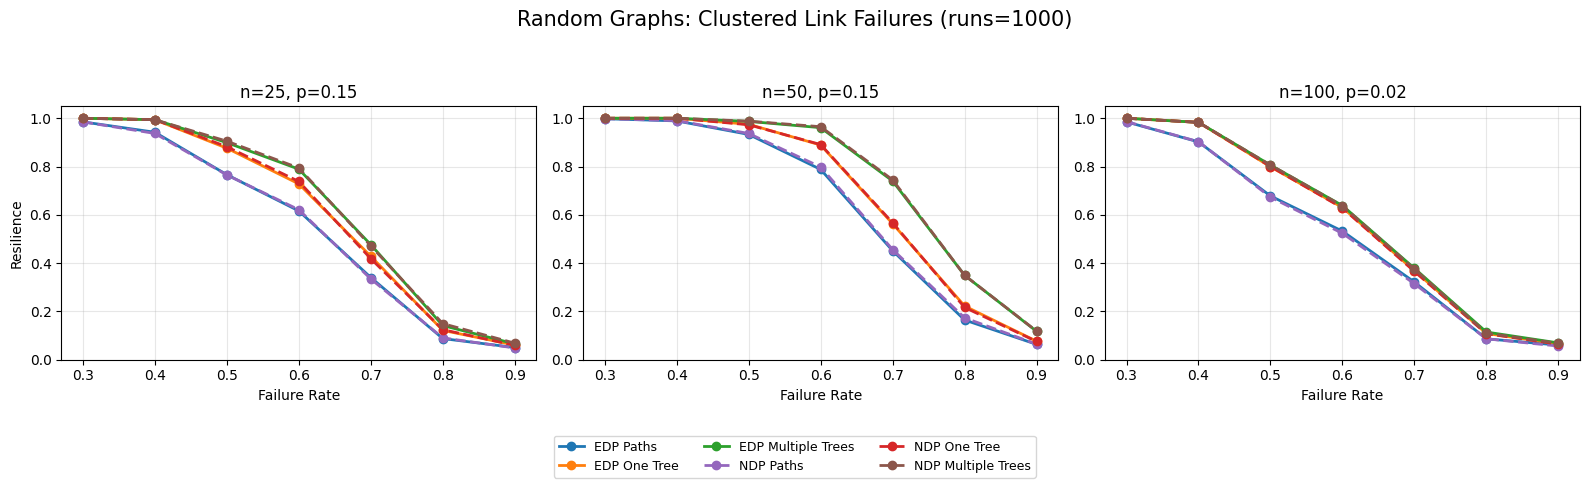

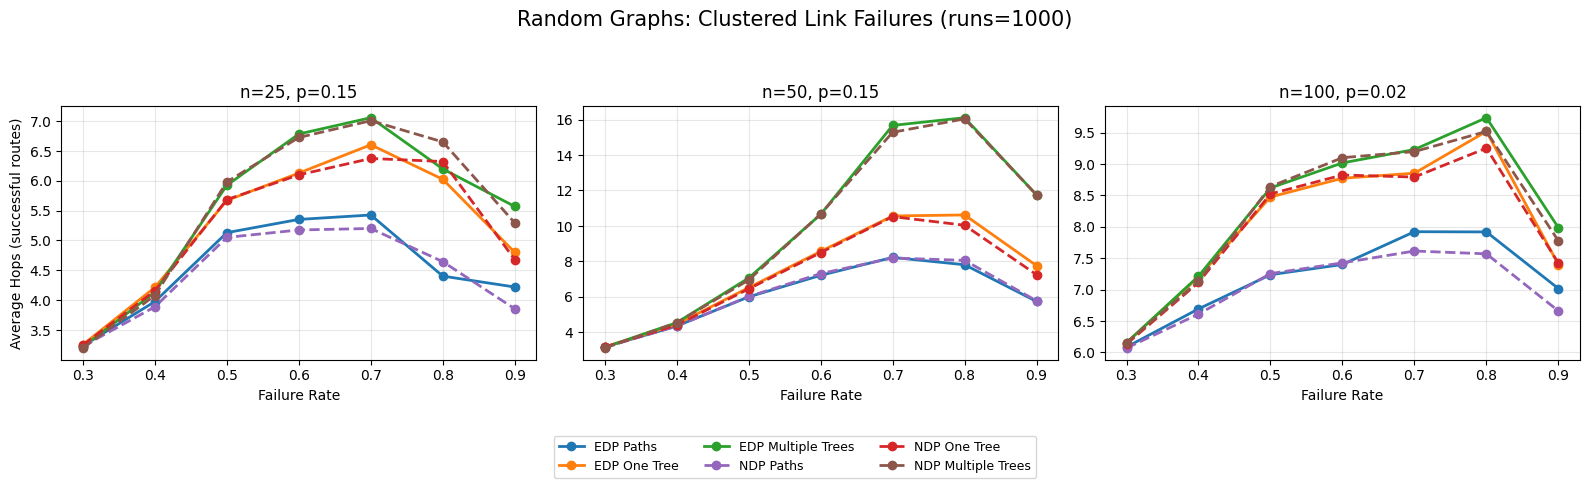

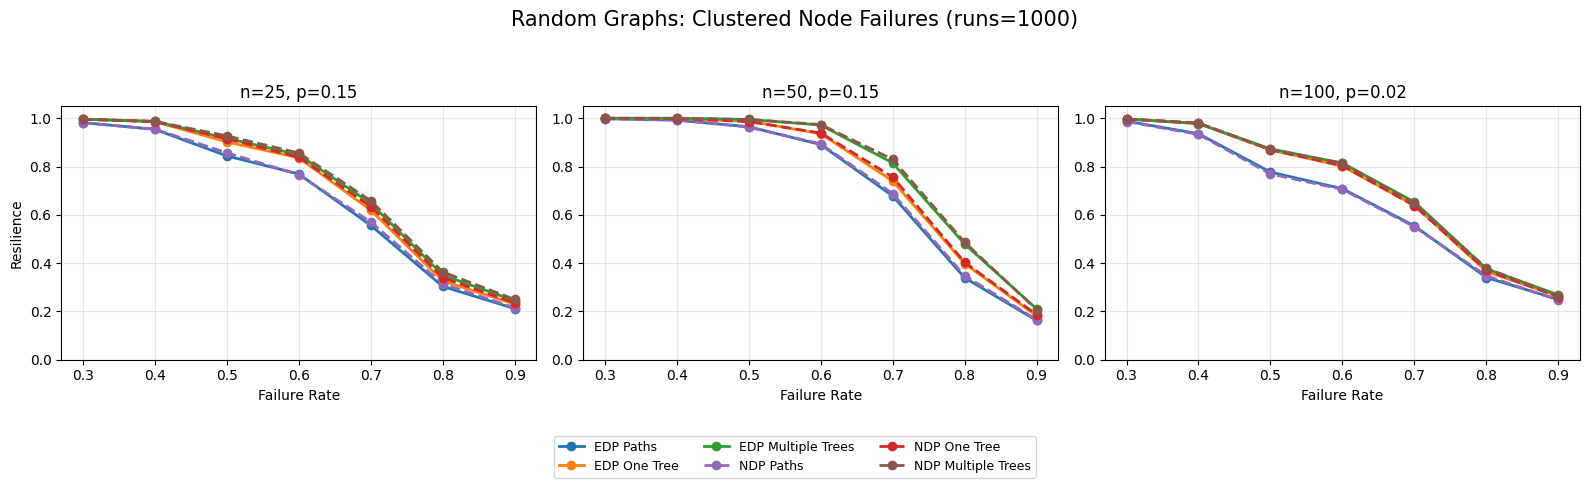

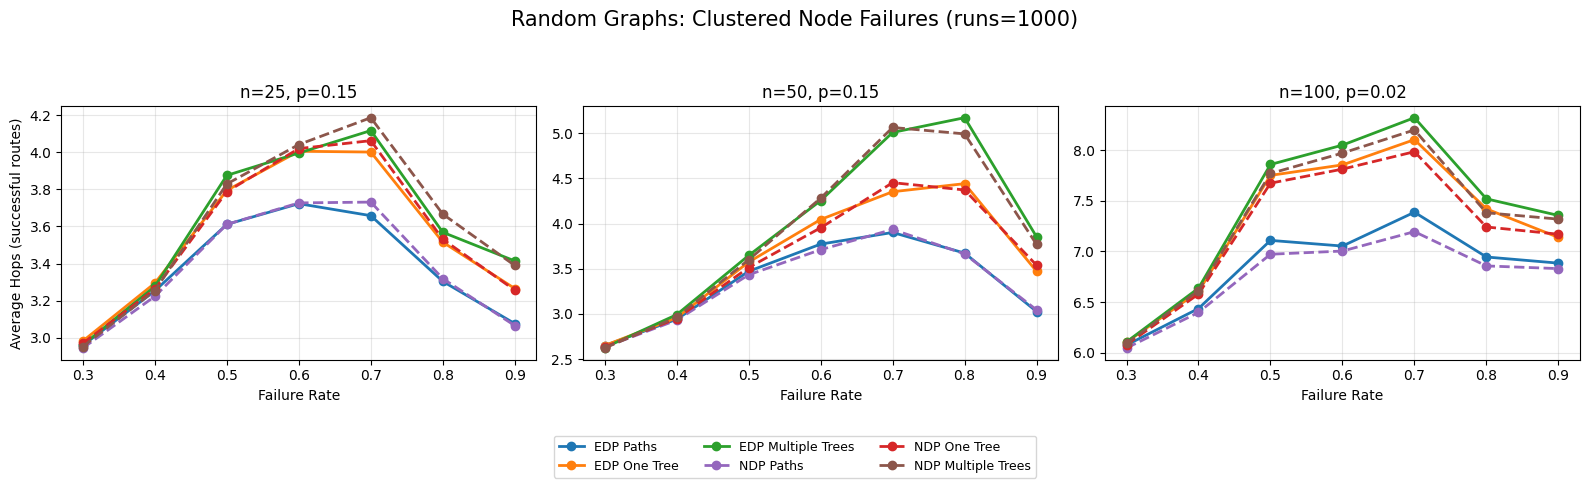

Summary: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\synthetic_graphs_runs1000\synthetic_graphs_runs1000_summary.csv
Hauptplotdateien: 16


In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary_path = OUTPUT_DIR / 'synthetic_graphs_runs1000_summary.csv'
summary.to_csv(summary_path, index=False)
main_plot_paths = plot_all_comparisons(
    summary=summary, datasets=list(DATASETS), display_names=DISPLAY_NAMES,
    algorithms=routing.ALGORITHMS, output_dir=OUTPUT_DIR,
    title_prefix='Random Graphs', runs=EXPECTED_RUNS,
    metrics=[
        ('resilience', 'Resilience', (0, 1.05)),
        ('avgHops', 'Average Hops (successful routes)', None),
    ],
)
assert len(main_plot_paths) == 16
assert all(path.exists() and path.stat().st_size > 0 for path in main_plot_paths)
print('Summary:', summary_path)
print('Hauptplotdateien:', len(main_plot_paths))

## Summary-CSV anzeigen

Diese Zelle liest die gespeicherte Summary-CSV erneut ein und zeigt sie als Tabelle im Notebook an.


In [10]:
import pandas as pd

summary_csv = OUTPUT_DIR / "synthetic_graphs_runs1000_summary.csv"
summary_df = pd.read_csv(summary_csv)

print("Summary-Datei:", summary_csv)
print("Zeilen:", len(summary_df))
display(summary_df)

Summary-Datei: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\synthetic_graphs_runs1000\synthetic_graphs_runs1000_summary.csv
Zeilen: 1380


,dataset,failureType,failureModel,failureParameter,algorithm,resilience,avgHops,avgStretch,samples,successes
0,n100_p002,link,clustered,0.3,edp_multiple_trees,1.000,6.155000,0.182000,1000,1000
1,n100_p002,link,clustered,0.3,edp_one_tree,1.000,6.155000,0.182000,1000,1000
2,n100_p002,link,clustered,0.3,edp_paths,0.985,6.086294,0.142132,1000,985
3,n100_p002,link,clustered,0.3,ndp_multiple_trees,1.000,6.155000,0.182000,1000,1000
4,n100_p002,link,clustered,0.3,ndp_one_tree,1.000,6.133000,0.160000,1000,1000
...,...,...,...,...,...,...,...,...,...,...
1375,n50_p015,node,random,16.8,edp_one_tree,0.056,3.196429,0.464286,1000,56
1376,n50_p015,node,random,16.8,edp_paths,0.049,2.755102,0.122449,1000,49
1377,n50_p015,node,random,16.8,ndp_multiple_trees,0.058,3.120690,0.344828,1000,58
1378,n50_p015,node,random,16.8,ndp_one_tree,0.055,3.145455,0.436364,1000,55


## Stretch-Plots

Diese Zelle erzeugt den durchschnittlichen Stretch separat, damit Resilience und Hops als Hauptplots übersichtlich bleiben.


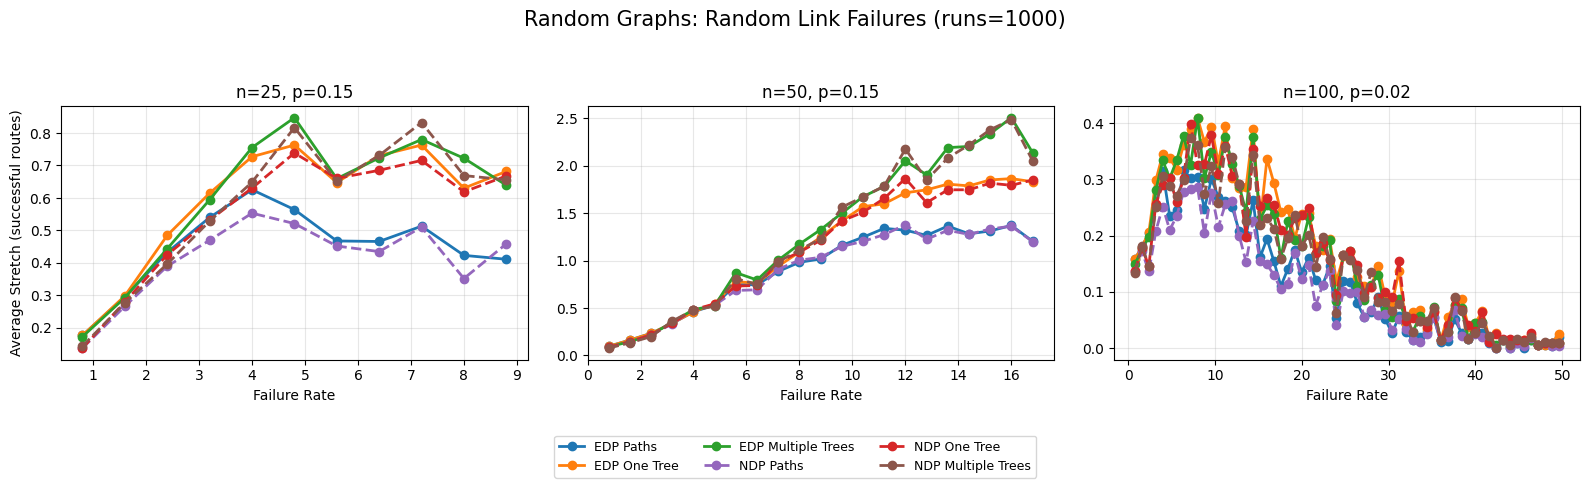

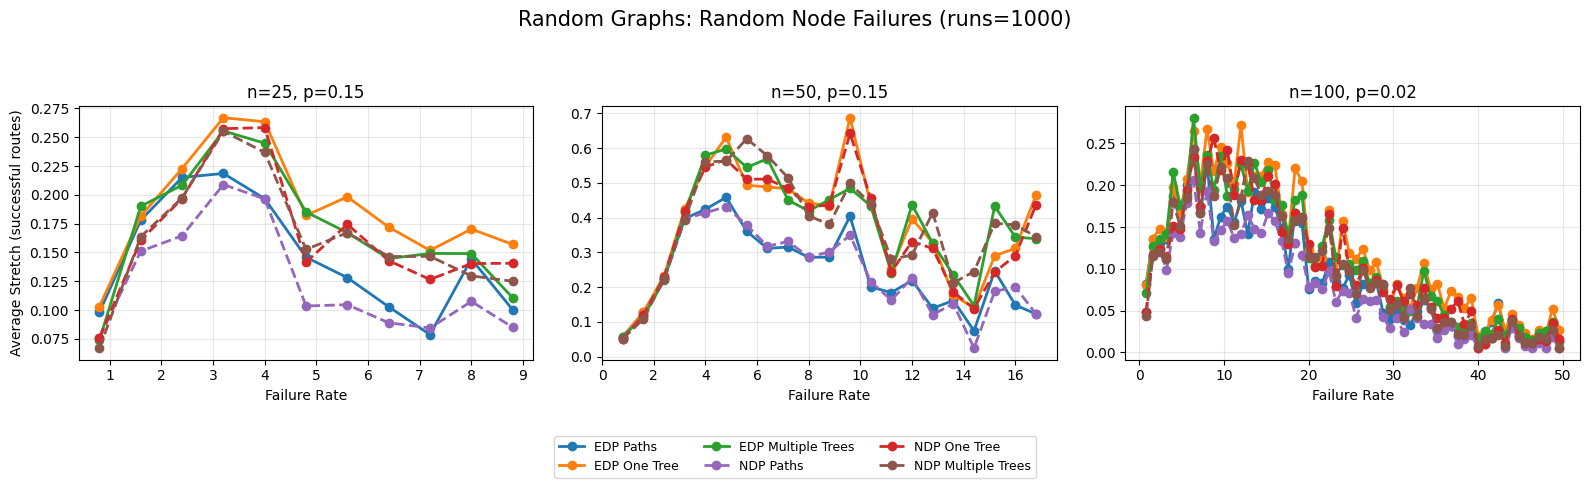

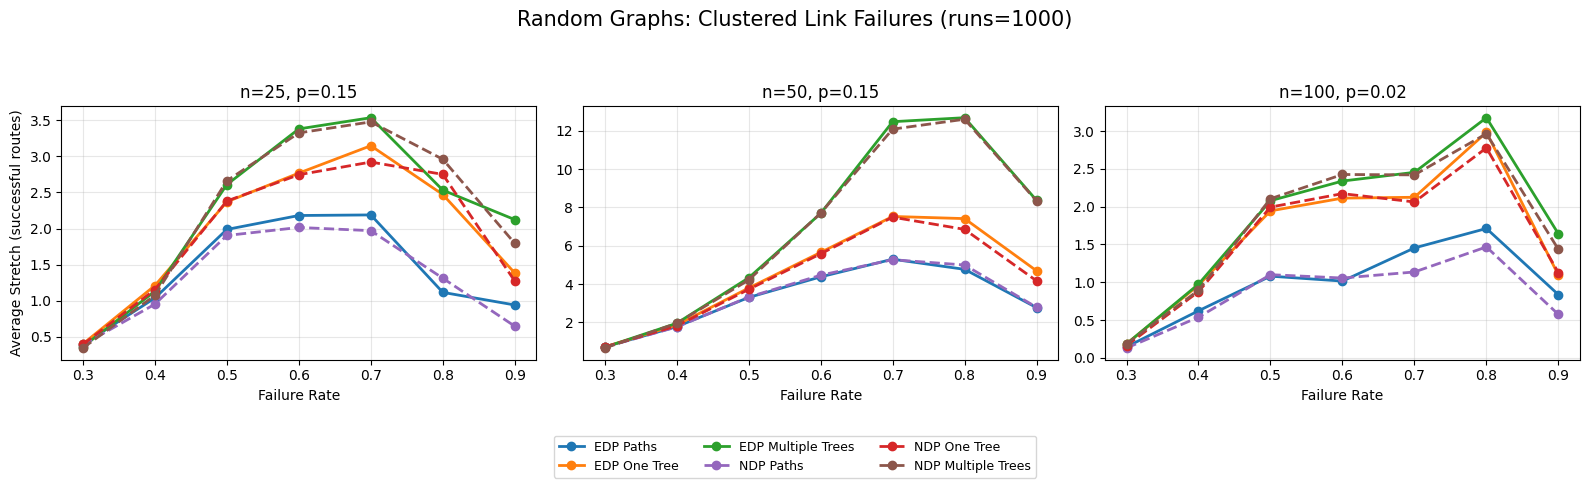

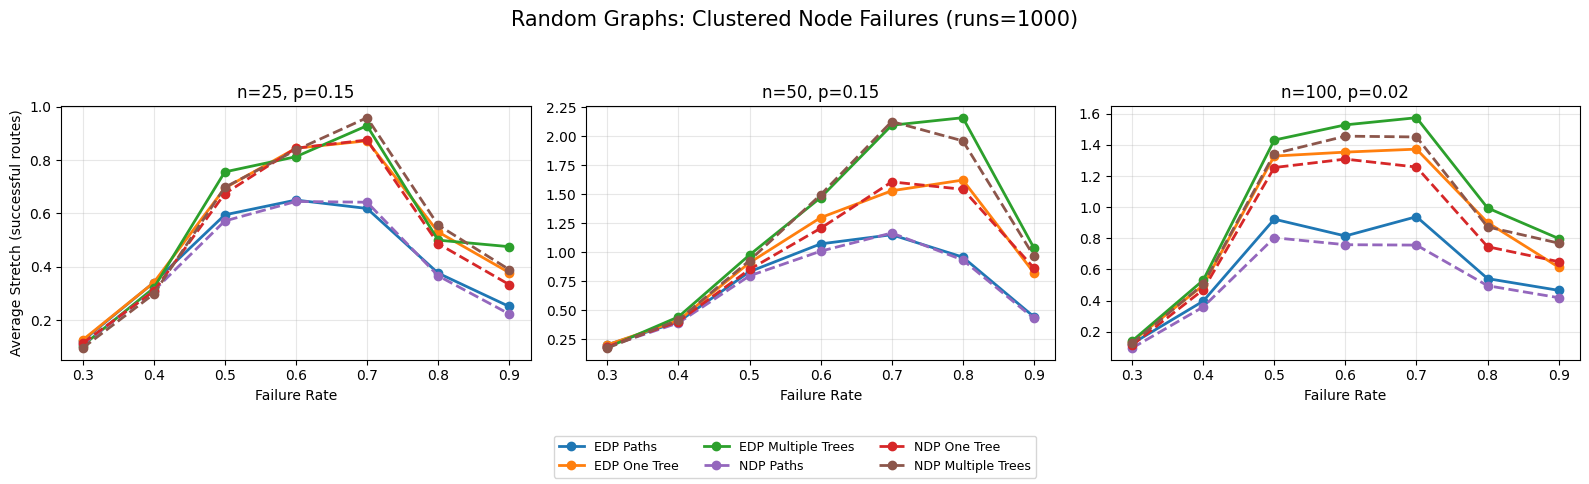

Stretch-Plotdateien: 8


In [11]:
stretch_plot_paths = plot_all_comparisons(
    summary=summary, datasets=list(DATASETS), display_names=DISPLAY_NAMES,
    algorithms=routing.ALGORITHMS, output_dir=OUTPUT_DIR,
    title_prefix='Random Graphs', runs=EXPECTED_RUNS,
    metrics=[('avgStretch', 'Average Stretch (successful routes)', None)],
)
assert len(stretch_plot_paths) == 8
assert all(path.exists() and path.stat().st_size > 0 for path in stretch_plot_paths)
print('Stretch-Plotdateien:', len(stretch_plot_paths))